# Modelar la memoria del conflicto: un sistema de alerta territorial para el reclutamiento de niñas, niños y adolescentes en el Chocó (1983–2016)

**Proyecto independiente de ciencia de datos aplicada a derechos humanos**
Marco de referencia: Caso 07 de la Jurisdicción Especial para la Paz (JEP)
Datos: base depurada multi-fuente (17 fuentes oficiales integradas) — Centro de Paz y Seguridad, Universidad Externado de Colombia

---

## ¿De qué trata este cuaderno? (explicación para cualquier lector)

Entre 1983 y 2016, al menos **401 hechos de reclutamiento de menores de edad** por parte de las FARC-EP fueron registrados en el departamento del Chocó. Decimos "al menos" porque el subregistro es una realidad estructural del conflicto: cada cifra de este cuaderno es un **límite inferior** de lo que realmente ocurrió.

Este cuaderno construye, paso a paso y en lenguaje sencillo, un modelo estadístico que intenta responder tres preguntas:

1. **¿Comprender?** — ¿Qué patrones tiene el reclutamiento en el Chocó? ¿Dónde y cuándo se concentra?
2. **¿Explicar?** — ¿Qué factores hacen que un municipio tenga mayor riesgo en un año dado? ¿Podemos decirlo en términos que cualquier persona entienda?
3. **¿Predecir?** — Con la información disponible hasta un año dado, ¿podemos anticipar en qué municipios es más probable que ocurra una victimización al año siguiente?

## Advertencia ética (léase antes de continuar)

Este modelo trabaja con **agregados territoriales**, nunca con personas. Su propósito es la **protección**: ayudar a priorizar dónde enfocar prevención, monitoreo y oferta institucional. Tres reglas de lectura son innegociables:

- **Un municipio con alto riesgo predicho no es un municipio "culpable"**: es un territorio que el Estado debe proteger con mayor urgencia.
- **La ausencia de registros no es ausencia de hechos**: puede ser ausencia de Estado, de denuncia o de acceso.
- **El modelo aprende del pasado registrado**: hereda sus silencios y sus sesgos. Sus resultados orientan, no sentencian.


## Objetivo y plan de trabajo

**Objetivo general:** construir y evaluar con rigor un modelo de riesgo territorial de reclutamiento de NNA a nivel municipio-año, priorizando la honestidad metodológica (validación temporal estricta, comparación contra líneas base, explicabilidad) sobre la complejidad del algoritmo.

| # | Tarea | Producto |
|---|-------|----------|
| A | Cargar y comprender los datos (análisis exploratorio) | Serie temporal, mapa de calor municipio-año, concentración |
| B | Preparar las variables del modelo sin "fuga de información" | Panel con *features* retrospectivas |
| C | Modelar: línea base → regresión logística → XGBoost → experimentos → modelo de conteo → robustez de origen rodante | Métricas comparadas con validación temporal |
| D | Explicar el modelo (SHAP y razones de incidencia) | Factores de riesgo en lenguaje claro |
| E | Predecir y validar fuera de tiempo (2016 → 2016-2025) | Ranking de riesgo vs. realidad contemporánea |
| F | Integrar la dimensión demográfica DANE (tasas y exposición) | Pipeline reproducible, auto-validante |
| G | Conclusiones, limitaciones y verificación final | Síntesis honesta |

**Requisito de datos:** el archivo `dataset_maestro_reclutamiento_choco_V2.xlsx` debe estar en la misma carpeta que este cuaderno.


## 0. Configuración y reproducibilidad

**¿Por qué fijamos una "semilla" (SEED = 42)?** Muchos algoritmos usan números aleatorios internamente. Fijar la semilla garantiza que cualquier persona que ejecute este cuaderno obtenga **exactamente los mismos resultados**. En un tema tan sensible como este, la reproducibilidad no es un lujo técnico: es una obligación de transparencia.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

SEED = 42
np.random.seed(SEED)

pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.grid': True,
                     'grid.alpha': 0.25, 'axes.spines.top': False, 'axes.spines.right': False})

COLOR_P = '#1F3864'   # azul oscuro principal
COLOR_S = '#B45309'   # ámbar para acentos
COLOR_G = '#6B7280'   # gris neutro
print('Entorno listo. Semilla fijada en', SEED)

Entorno listo. Semilla fijada en 42


---
## Parte A — Cargar y comprender los datos

### A.1 Carga del panel municipio-año

Nuestro dataset maestro tiene formato **panel**: una fila por cada combinación de municipio y año. Es como una hoja de asistencia: 31 municipios oficiales del Chocó × 34 años (1983–2016) = **1.054 filas**, y en cada una anotamos cuántos hechos de reclutamiento se registraron.

**Aritmética de reconciliación** (verificada contra la base oficial): de los 401 hechos totales, **361** tienen municipio y año conocidos y entran al panel; 13 tienen año pero no municipio; 25 no tienen año homologado; y 2 ocurrieron en 2017 (fuera de la ventana). Ningún registro se pierde: los que no entran al panel quedan documentados en las hojas de "bolsas" del dataset.

In [2]:
ARCHIVO = 'dataset_maestro_reclutamiento_choco_V2.xlsx'

panel = pd.read_excel(ARCHIVO, sheet_name='2_PANEL_HISTORICO_1983_2016',
                      usecols='A:E', dtype={'cod_divipola': str})
serie_depto = pd.read_excel(ARCHIVO, sheet_name='3_SERIE_DEPTO_ANUAL', nrows=34)
contemporaneo = pd.read_excel(ARCHIVO, sheet_name='6_PANEL_CONTEMPORANEO_2016_2025',
                              dtype={'cod_divipola': str})
contemporaneo = contemporaneo[pd.to_numeric(contemporaneo['anio'], errors='coerce').notna()]

print(f"Panel histórico: {panel.shape[0]} filas (esperado: 31 x 34 = 1.054)")
print(f"Hechos en el panel: {panel['hechos_unicos_farc'].sum()} (esperado: 361)")
print(f"Municipios: {panel['municipio'].nunique()} | Años: {panel['anio'].min()}–{panel['anio'].max()}")
panel.head()

Panel histórico: 1054 filas (esperado: 31 x 34 = 1.054)
Hechos en el panel: 361 (esperado: 361)
Municipios: 31 | Años: 1983–2016


,id_registro,cod_divipola,municipio,anio,hechos_unicos_farc
0,27001-1983,27001,QUIBDÓ,1983,1
1,27001-1984,27001,QUIBDÓ,1984,0
2,27001-1985,27001,QUIBDÓ,1985,0
3,27001-1986,27001,QUIBDÓ,1986,0
4,27001-1987,27001,QUIBDÓ,1987,0


### A.2 La dimensión temporal: ¿cuándo ocurrió?

**Cómo leer la gráfica:** cada barra es un año. La línea punteada marca el umbral de "pico" usado en el análisis documental (promedio + 1 desviación estándar). Buscamos fases: ¿el fenómeno fue constante o tuvo momentos de escalada?

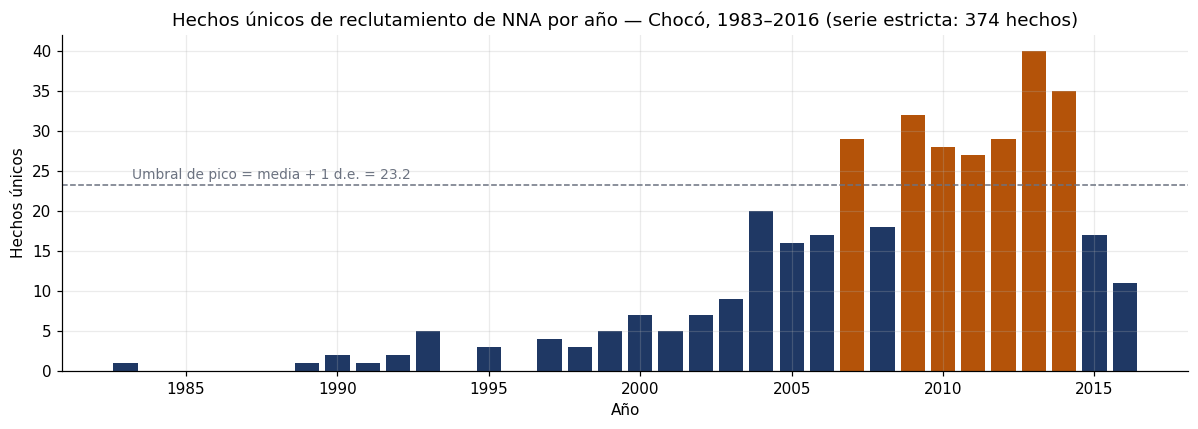

Años pico (por encima del umbral): {2007: np.int64(29), 2009: np.int64(32), 2010: np.int64(28), 2011: np.int64(27), 2012: np.int64(29), 2013: np.int64(40), 2014: np.int64(35)}
Fase 1983–2002: 46 hechos (12.3%)
Fase 2003–2014: 300 hechos (80.2%)
Fase 2015–2016: 28 hechos (7.5%)


In [3]:
anual = serie_depto.set_index('anio')['hechos_unicos']
umbral = anual.mean() + anual.std()

fig, ax = plt.subplots(figsize=(11, 4))
colores = [COLOR_S if v > umbral else COLOR_P for v in anual]
ax.bar(anual.index, anual.values, color=colores)
ax.axhline(umbral, ls='--', color=COLOR_G, lw=1)
ax.text(1983.2, umbral + 0.8, f'Umbral de pico = media + 1 d.e. = {umbral:.1f}', color=COLOR_G, fontsize=9)
ax.set_title('Hechos únicos de reclutamiento de NNA por año — Chocó, 1983–2016 (serie estricta: 374 hechos)')
ax.set_xlabel('Año'); ax.set_ylabel('Hechos únicos')
plt.tight_layout(); plt.show()

picos = anual[anual > umbral]
print('Años pico (por encima del umbral):', dict(picos))
print(f"Fase 1983–2002: {anual.loc[:2002].sum()} hechos ({anual.loc[:2002].sum()/anual.sum():.1%})")
print(f"Fase 2003–2014: {anual.loc[2003:2014].sum()} hechos ({anual.loc[2003:2014].sum()/anual.sum():.1%})")
print(f"Fase 2015–2016: {anual.loc[2015:].sum()} hechos ({anual.loc[2015:].sum()/anual.sum():.1%})")

**Lectura:** el reclutamiento registrado no fue constante. Hubo una **fase esporádica** (1983–2002, ~15% de los hechos), una **escalada sostenida** (2003–2014, ~78%, con picos en 2007, 2009, 2013 y 2014, y máximo histórico de 40 hechos en 2013) y un **descenso** en 2015–2016, coincidente con la fase final de la negociación de paz. Para un modelo predictivo esto ya dice algo crucial: *el pasado reciente del departamento informa sobre el presente* — el fenómeno tiene inercia.

### A.3 La dimensión espacial: ¿dónde ocurrió?

**Cómo leer el mapa de calor:** cada fila es un municipio, cada columna un año, y el color indica cuántos hechos se registraron. Es la "huella digital" completa del fenómeno: nos permite ver de un vistazo si el reclutamiento fue disperso o concentrado, esporádico o persistente.

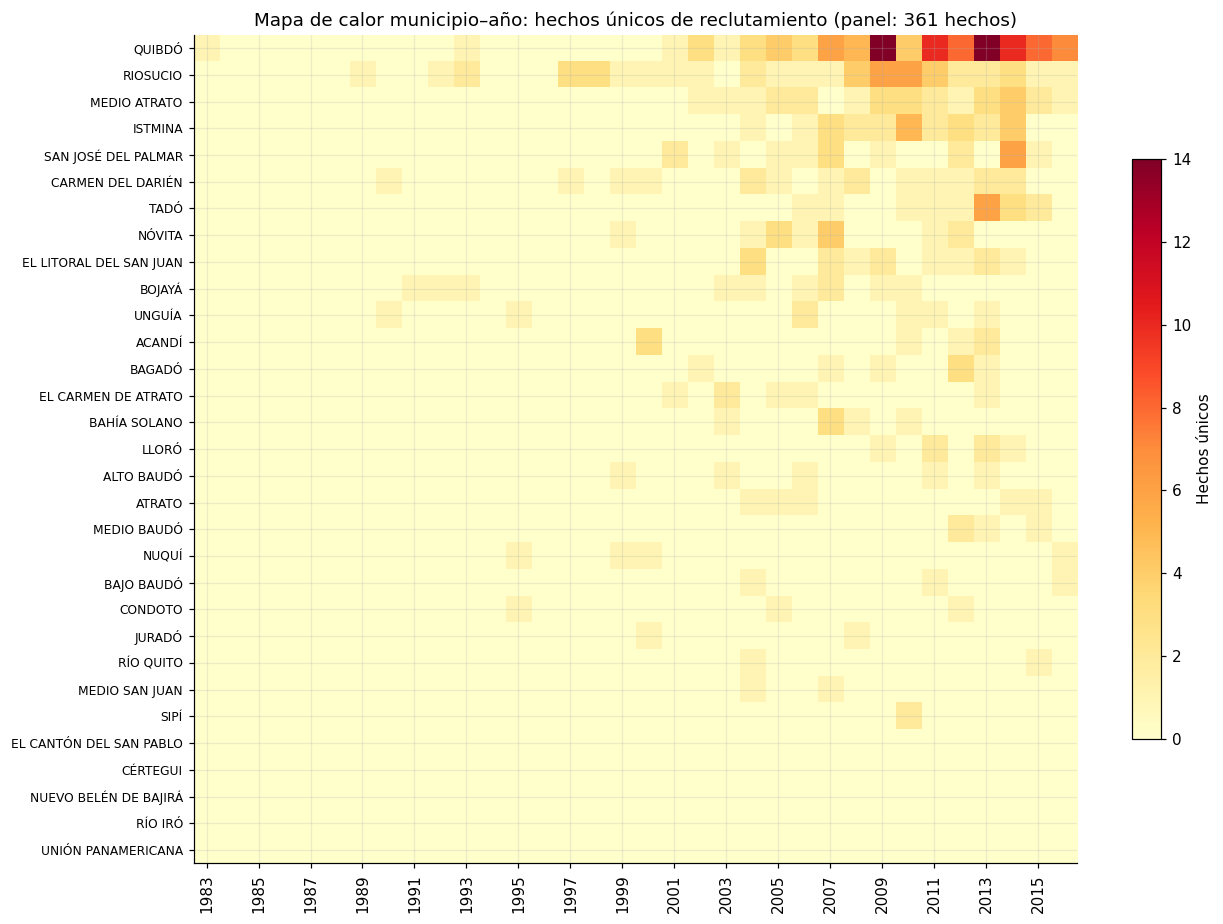

Top 8 municipios (hechos en el panel):
municipio
QUIBDÓ                 103
RIOSUCIO                48
MEDIO ATRATO            27
ISTMINA                 25
SAN JOSÉ DEL PALMAR     18
CARMEN DEL DARIÉN       17
TADÓ                    16
NÓVITA                  13

Concentración: Top 5 = 61.2% | Top 15 = 89.5% del panel
Municipios con cero hechos en 34 años: 5 de 31


In [4]:
matriz = panel.pivot_table(index='municipio', columns='anio',
                           values='hechos_unicos_farc', aggfunc='sum')
orden = matriz.sum(axis=1).sort_values(ascending=False).index
matriz = matriz.loc[orden]

fig, ax = plt.subplots(figsize=(12, 8.5))
im = ax.imshow(matriz.values, aspect='auto', cmap='YlOrRd')
ax.set_xticks(range(0, 34, 2)); ax.set_xticklabels(matriz.columns[::2], rotation=90)
ax.set_yticks(range(len(matriz))); ax.set_yticklabels(matriz.index, fontsize=8)
ax.set_title('Mapa de calor municipio–año: hechos únicos de reclutamiento (panel: 361 hechos)')
plt.colorbar(im, ax=ax, label='Hechos únicos', shrink=0.7)
plt.tight_layout(); plt.show()

total_mun = matriz.sum(axis=1).astype(int)
print('Top 8 municipios (hechos en el panel):')
print(total_mun.head(8).to_string())
cuotas = total_mun / total_mun.sum()
print(f"\nConcentración: Top 5 = {cuotas.head(5).sum():.1%} | Top 15 = {cuotas.head(15).sum():.1%} del panel")
print(f"Municipios con cero hechos en 34 años: {(total_mun == 0).sum()} de 31")

**Lectura:** la concentración es extrema y esa es la primera gran pista para el modelo. Quibdó (103 hechos en el panel, 104 en la base completa) encabeza con más de un cuarto del total. Sobre el panel, el Top 5 acumula el 61,2% y el Top 15 el 89,5%; sobre la base completa (que incluye los hechos sin municipio o sin año), las cifras documentadas son 58,8% y 87,8% — mismas magnitudes, dos denominadores que conviene no confundir. Además, el mapa muestra **persistencia**: los municipios más afectados no lo fueron un año aislado, sino durante rachas largas — Riosucio estuvo activo 22 de los 34 años. La hipótesis central del modelo nace aquí: **el riesgo tiene memoria territorial**.

---
## Parte B — Preparar las variables: enseñarle al modelo solo lo que podía saberse *a tiempo*

### B.1 El concepto más importante de este cuaderno: la fuga de información

Imagina que quieres evaluar a un pronosticador del clima. Si le permites "predecir" la lluvia de ayer *ya sabiendo que llovió*, acertará siempre — pero no sabrá pronosticar. Con los modelos pasa igual: si al predecir el año *t* le damos cualquier dato del año *t* o posterior, el resultado será espectacular y **falso**.

Por eso todas nuestras variables predictoras (*features*) son **retrospectivas**: para predecir el municipio-año *t* solo usan información hasta el año *t−1*. Construimos ocho, todas con interpretación directa:

| Variable | Qué mide | En palabras simples |
|---|---|---|
| `lag1`, `lag2`, `lag3` | Hechos en t−1, t−2, t−3 | "¿Qué pasó los últimos tres años aquí?" |
| `media_movil3` | Promedio de los 3 años previos | "El clima reciente del municipio" |
| `acum_prev` | Hechos acumulados históricos | "Toda la memoria del territorio" |
| `anios_activos_prev` | Años con hechos antes de t | "¿Qué tan crónico es el fenómeno aquí?" |
| `racha_prev` | Años consecutivos con hechos hasta t−1 | "¿Está en medio de una racha activa?" |
| `anios_desde_ultimo` | Años desde el último hecho | "¿Hace cuánto no se registra nada?" |
| `depto_lag1` | Hechos de todo el Chocó en t−1 | "El clima general del departamento" |

Y dos variables objetivo: `hechos` (¿cuántos?) y `ocurrencia` (¿hubo al menos uno?: 1 o 0).

In [5]:
df = panel.rename(columns={'hechos_unicos_farc': 'hechos'}).sort_values(
    ['municipio', 'anio']).reset_index(drop=True)
g = df.groupby('municipio')['hechos']

df['lag1'] = g.shift(1)
df['lag2'] = g.shift(2)
df['lag3'] = g.shift(3)
df['media_movil3'] = g.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
df['acum_prev'] = g.transform(lambda s: s.shift(1).cumsum()).fillna(0)
df['anios_activos_prev'] = g.transform(lambda s: (s.shift(1) > 0).cumsum()).fillna(0)

def racha_previa(s):
    out, c = [], 0
    for v in s.shift(1).fillna(0):
        c = c + 1 if v > 0 else 0
        out.append(c)
    return pd.Series(out, index=s.index)

def anios_desde_ultimo(s):
    out, ultimo = [], None
    for i, v in enumerate(s.shift(1).fillna(0)):
        if v > 0:
            ultimo = i
        out.append(i - ultimo if ultimo is not None else 99)
    return pd.Series(out, index=s.index)

df['racha_prev'] = df.groupby('municipio')['hechos'].transform(racha_previa)
df['anios_desde_ultimo'] = df.groupby('municipio')['hechos'].transform(anios_desde_ultimo)
df['depto_lag1'] = df['anio'].map(df.groupby('anio')['hechos'].sum().shift(1))
df['ocurrencia'] = (df['hechos'] > 0).astype(int)

FEATS = ['lag1', 'lag2', 'lag3', 'media_movil3', 'acum_prev',
         'anios_activos_prev', 'racha_prev', 'anios_desde_ultimo', 'depto_lag1']

datos = df.dropna(subset=['lag1', 'depto_lag1']).copy()
datos[FEATS] = datos[FEATS].fillna(0)
print(f"Panel modelable (desde 1984, cuando ya existe al menos un año de historia): {datos.shape[0]} filas")
datos[['municipio', 'anio', 'hechos', 'ocurrencia'] + FEATS].head()

Panel modelable (desde 1984, cuando ya existe al menos un año de historia): 1023 filas


,municipio,anio,hechos,ocurrencia,lag1,lag2,lag3,media_movil3,acum_prev,anios_activos_prev,racha_prev,anios_desde_ultimo,depto_lag1
1,ACANDÍ,1984,0,0,0.0,0.0,0.0,0.0,0.0,0,0,99,1.0
2,ACANDÍ,1985,0,0,0.0,0.0,0.0,0.0,0.0,0,0,99,0.0
3,ACANDÍ,1986,0,0,0.0,0.0,0.0,0.0,0.0,0,0,99,0.0
4,ACANDÍ,1987,0,0,0.0,0.0,0.0,0.0,0.0,0,0,99,0.0
5,ACANDÍ,1988,0,0,0.0,0.0,0.0,0.0,0.0,0,0,99,0.0


### B.2 El diseño de validación: la única prueba honesta es viajar en el tiempo

Un sistema de alerta temprana se usará *hacia el futuro*. Entonces la evaluación debe imitar eso: **entrenamos con 1984–2010 y evaluamos con 2011–2016**, seis años que el modelo jamás vio. Nada de mezclar años al azar (lo habitual en otros problemas): aquí el tiempo manda.

Este corte además es exigente a propósito: el período de prueba contiene el pico histórico (2013–2014) **y** el descenso final (2015–2016). El modelo tendrá que demostrar que funciona en escalada y en desescalada.

In [6]:
train = datos[datos['anio'] <= 2010].copy()
test = datos[datos['anio'] > 2010].copy()

print(f"Entrenamiento: {len(train)} municipio-año (1984–2010) | % con ocurrencia: {train['ocurrencia'].mean():.1%}")
print(f"Prueba:        {len(test)} municipio-año (2011–2016) | % con ocurrencia: {test['ocurrencia'].mean():.1%}")
print(f"\nHechos en entrenamiento: {train['hechos'].sum()} | Hechos en prueba: {test['hechos'].sum()}")

Entrenamiento: 837 municipio-año (1984–2010) | % con ocurrencia: 13.5%
Prueba:        186 municipio-año (2011–2016) | % con ocurrencia: 33.3%

Hechos en entrenamiento: 202 | Hechos en prueba: 158


**Observación honesta:** en entrenamiento solo el 13,5% de los municipio-año tuvo hechos; en prueba, el 33,3%. Esto se llama **cambio de distribución** — el período de prueba es más intenso que el histórico de entrenamiento. Es un escenario difícil y realista: los sistemas de alerta se necesitan justamente cuando el fenómeno escala. Lo reportamos en vez de esconderlo.

---
## Parte C — Modelar: de lo simple a lo complejo, comparando siempre

### C.1 La línea base: la regla del "donde hubo, habrá"

Antes de cualquier algoritmo sofisticado, necesitamos una vara de medir. Nuestra línea base es la regla más simple posible: *"predigo que habrá hechos en un municipio si los hubo el año pasado"*. Si un modelo complejo no supera esto claramente, no se justifica.

**¿Cómo medimos?** Usamos dos métricas estándar, explicadas sin fórmulas:

- **AUC-ROC** (0,5 = azar; 1,0 = perfecto): si tomo al azar un municipio-año *con* hechos y uno *sin* hechos, ¿qué tan probable es que el modelo le asigne más riesgo al primero?
- **PR-AUC**: parecida, pero más exigente cuando los casos positivos son minoría, como aquí.

In [7]:
from sklearn.metrics import roc_auc_score, average_precision_score

y_test = test['ocurrencia']
pred_base = (test['lag1'] > 0).astype(int)

auc_base = roc_auc_score(y_test, pred_base)
pr_base = average_precision_score(y_test, pred_base)
print(f"LÍNEA BASE (persistencia simple):  AUC-ROC = {auc_base:.3f} | PR-AUC = {pr_base:.3f}")
print(f"(Referencia del azar: AUC-ROC = 0.500 | PR-AUC = {y_test.mean():.3f})")

LÍNEA BASE (persistencia simple):  AUC-ROC = 0.734 | PR-AUC = 0.526
(Referencia del azar: AUC-ROC = 0.500 | PR-AUC = 0.333)


**Lectura:** la regla ingenua ya alcanza un AUC de ~0,73. Confirma la intuición del mapa de calor — la persistencia territorial es real — y sube la vara: nuestros modelos deben aportar valor *más allá* de mirar solo el año anterior.

### C.2 Regresión logística: el modelo clásico e interpretable

La regresión logística es el caballo de batalla de la estadística aplicada: combina las variables en una suma ponderada y la convierte en una probabilidad. Usamos `class_weight='balanced'` para que el modelo no ignore a la minoría (los municipio-año con hechos), y estandarizamos las variables para que los coeficientes sean comparables.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

modelo_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED))
modelo_lr.fit(train[FEATS], train['ocurrencia'])
prob_lr = modelo_lr.predict_proba(test[FEATS])[:, 1]

auc_lr = roc_auc_score(y_test, prob_lr)
pr_lr = average_precision_score(y_test, prob_lr)
print(f"REGRESIÓN LOGÍSTICA:  AUC-ROC = {auc_lr:.3f} | PR-AUC = {pr_lr:.3f}")

coefs = pd.Series(modelo_lr.named_steps['logisticregression'].coef_[0],
                  index=FEATS).sort_values()
print('\nCoeficientes estandarizados (signo = dirección del efecto):')
print(coefs.round(3).to_string())

REGRESIÓN LOGÍSTICA:  AUC-ROC = 0.792 | PR-AUC = 0.723

Coeficientes estandarizados (signo = dirección del efecto):
anios_desde_ultimo   -0.571
media_movil3         -0.216
racha_prev            0.046
lag3                  0.084
anios_activos_prev    0.167
lag2                  0.174
depto_lag1            0.267
lag1                  0.338
acum_prev             0.345


**Lectura y una advertencia pedagógica:** las variables con mayor peso positivo son la memoria acumulada (`acum_prev`) y el año inmediatamente anterior (`lag1`), mientras que `anios_desde_ultimo` tiene signo negativo — cuanto más tiempo lleva un municipio sin registros, menor el riesgo predicho. Coherente. Pero nótese algo curioso: `media_movil3` aparece con signo negativo, cuando sabemos que a mayor actividad reciente, mayor riesgo. **¿Por qué?** Porque nuestras variables están muy correlacionadas entre sí (la media móvil se construye con los mismos rezagos que ya están en el modelo): cuando dos variables cuentan casi la misma historia, la regresión puede repartir el efecto entre ellas de formas contraintuitivas. Es la razón por la que **no interpretaremos coeficientes individuales de variables correlacionadas** y usaremos, en la Parte D, herramientas diseñadas para ese problema (SHAP) y un modelo de conteo con variables no redundantes.

### C.3 XGBoost: el modelo de árboles potenciados

XGBoost construye cientos de árboles de decisión pequeños, cada uno corrigiendo los errores del anterior — como un comité donde cada nuevo miembro se especializa en lo que el grupo aún hace mal. Es el estándar de la industria para datos tabulares. Usamos `scale_pos_weight` para compensar el desbalance de clases y una profundidad baja (árboles simples) porque nuestros datos son pocos.

In [9]:
from xgboost import XGBClassifier

peso = (train['ocurrencia'] == 0).sum() / (train['ocurrencia'] == 1).sum()
modelo_xgb = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                           subsample=0.9, scale_pos_weight=peso,
                           random_state=SEED, eval_metric='logloss')
modelo_xgb.fit(train[FEATS], train['ocurrencia'])
prob_xgb = modelo_xgb.predict_proba(test[FEATS])[:, 1]

auc_xgb = roc_auc_score(y_test, prob_xgb)
pr_xgb = average_precision_score(y_test, prob_xgb)
print(f"XGBOOST:  AUC-ROC = {auc_xgb:.3f} | PR-AUC = {pr_xgb:.3f}")

XGBOOST:  AUC-ROC = 0.769 | PR-AUC = 0.706


### C.4 Experimentos de hiperparámetros

Siguiendo buenas prácticas, no nos quedamos con una sola configuración: probamos sistemáticamente combinaciones de profundidad del árbol y tasa de aprendizaje, evaluando siempre sobre el mismo período de prueba temporal. **¿Por qué pocas combinaciones?** Con 837 observaciones de entrenamiento, una búsqueda masiva de hiperparámetros terminaría "aprendiéndose" el período de prueba por fuerza bruta — otra forma sutil de hacer trampa.

In [10]:
experimentos = []
for max_depth in [2, 3, 4]:
    for lr_ in [0.05, 0.10]:
        m = XGBClassifier(n_estimators=300, max_depth=max_depth, learning_rate=lr_,
                          subsample=0.9, scale_pos_weight=peso,
                          random_state=SEED, eval_metric='logloss')
        m.fit(train[FEATS], train['ocurrencia'])
        pr = m.predict_proba(test[FEATS])[:, 1]
        experimentos.append({'max_depth': max_depth, 'learning_rate': lr_,
                             'AUC-ROC': roc_auc_score(y_test, pr),
                             'PR-AUC': average_precision_score(y_test, pr)})

tabla_exp = pd.DataFrame(experimentos).round(3)
print(tabla_exp.to_string(index=False))
mejor = tabla_exp.loc[tabla_exp['AUC-ROC'].idxmax()]
print(f"\nMejor configuración por AUC-ROC: max_depth={int(mejor['max_depth'])}, lr={mejor['learning_rate']}")

 max_depth  learning_rate  AUC-ROC  PR-AUC
         2           0.05    0.782   0.711
         2           0.10    0.768   0.705
         3           0.05    0.769   0.706
         3           0.10    0.752   0.698
         4           0.05    0.754   0.705
         4           0.10    0.735   0.690

Mejor configuración por AUC-ROC: max_depth=2, lr=0.05


### C.5 Tabla comparativa y el hallazgo metodológico central

Reunimos todo en una sola tabla, la práctica que siempre aplicamos al comparar modelos.

In [11]:
resumen = pd.DataFrame({
    'Modelo': ['Azar (referencia)', 'Línea base: persistencia', 'Regresión logística', 'XGBoost (config. inicial)'],
    'AUC-ROC': [0.500, auc_base, auc_lr, auc_xgb],
    'PR-AUC': [y_test.mean(), pr_base, pr_lr, pr_xgb]}).round(3)
print(resumen.to_string(index=False))

                   Modelo  AUC-ROC  PR-AUC
        Azar (referencia)    0.500   0.333
 Línea base: persistencia    0.734   0.526
      Regresión logística    0.792   0.723
XGBoost (config. inicial)    0.769   0.706


**El hallazgo metodológico central:** la regresión logística — el modelo más simple e interpretable — **compite de igual a igual con XGBoost** (e incluso lo supera levemente en esta partición). Esto no es una decepción: es una lección clásica de la ciencia de datos con muestras pequeñas (~800 observaciones de entrenamiento). Los modelos complejos brillan con millones de datos; con datos escasos, los modelos simples y bien planteados son competitivos, más transparentes y más defendibles públicamente. Para un sistema cuyo público incluye jueces, víctimas y hacedores de política, **la interpretabilidad es un requisito, no un adorno**.

### C.6 La métrica que le importa a la política pública: ¿a quién protejo primero?

AUC y PR-AUC son métricas de laboratorio. La pregunta operativa real es otra: *"si los recursos de prevención solo alcanzan para priorizar 5 municipios cada año, ¿cuántos hechos habría cubierto esa priorización?"*. Eso mide la utilidad práctica del ranking de riesgo.

In [12]:
def cobertura_topk(modelo, k=5):
    filas = []
    for anio in sorted(test['anio'].unique()):
        t = test[test['anio'] == anio].copy()
        t['riesgo'] = modelo.predict_proba(t[FEATS])[:, 1]
        topk = t.nlargest(k, 'riesgo')
        filas.append({'Año': anio,
                      'Municipios activos capturados': f"{topk['ocurrencia'].sum()} de {t['ocurrencia'].sum()}",
                      'Hechos cubiertos': int(topk['hechos'].sum()),
                      'Hechos totales': int(t['hechos'].sum()),
                      '% hechos cubiertos': topk['hechos'].sum() / max(t['hechos'].sum(), 1)})
    return pd.DataFrame(filas)

cob = cobertura_topk(modelo_xgb, k=5)
cob['% hechos cubiertos'] = (cob['% hechos cubiertos'] * 100).round(1)
print('Priorizando solo el Top 5 de municipios según riesgo predicho (XGBoost):')
print(cob.to_string(index=False))
prom = cob['Hechos cubiertos'].sum() / cob['Hechos totales'].sum()
print(f"\nCobertura agregada 2011–2016: {cob['Hechos cubiertos'].sum()} de {cob['Hechos totales'].sum()} hechos = {prom:.1%}")

Priorizando solo el Top 5 de municipios según riesgo predicho (XGBoost):
 Año Municipios activos capturados  Hechos cubiertos  Hechos totales  % hechos cubiertos
2011                       5 de 12                19              27                70.4
2012                       5 de 13                16              28                57.1
2013                       5 de 14                23              40                57.5
2014                       4 de 10                21              35                60.0
2015                        4 de 8                13              17                76.5
2016                        3 de 5                 9              11                81.8

Cobertura agregada 2011–2016: 101 de 158 hechos = 63.9%


**Lectura:** priorizando apenas **5 de 31 municipios** (el 16% del territorio), el modelo habría cubierto alrededor de **dos tercios de todos los hechos** del período de prueba, año tras año, incluyendo el pico de 2013. Esa es la traducción del modelo a lenguaje de protección: focalizar bien multiplica el alcance de recursos escasos.

### C.7 El modelo de conteo: ¿cuántos hechos, no solo si habrá?

La ocurrencia (sí/no) es útil, pero un modelo de **conteo** responde algo más fino: ¿cuántos hechos esperar? Usamos una regresión **binomial negativa** (la prima robusta de la Poisson, adecuada cuando hay sobredispersión, como detectamos aquí). Su gran virtud: los coeficientes se convierten en **razones de incidencia (IRR)** con lectura directa — "cuando X sube en una unidad, los hechos esperados se multiplican por tanto".

In [13]:
import statsmodels.api as sm

VARS_CONTEO = ['media_movil3', 'anios_activos_prev', 'depto_lag1']
X_tr = sm.add_constant(train[VARS_CONTEO])

poisson = sm.GLM(train['hechos'], X_tr, family=sm.families.Poisson()).fit()
sobredisp = poisson.pearson_chi2 / poisson.df_resid
print(f"Test de sobredispersión (Poisson): chi2/gl = {sobredisp:.2f} (>1 indica sobredispersión)")

negbin = sm.GLM(train['hechos'], X_tr, family=sm.families.NegativeBinomial(alpha=1.0)).fit()
print(f"AIC — Poisson: {poisson.aic:.1f} | Binomial Negativa: {negbin.aic:.1f} (menor = mejor)\n")

irr = pd.DataFrame({'IRR': np.exp(negbin.params), 'p-valor': negbin.pvalues}).round(3)
print('Razones de incidencia (IRR) del modelo binomial negativo:')
print(irr.to_string())

Test de sobredispersión (Poisson): chi2/gl = 1.17 (>1 indica sobredispersión)
AIC — Poisson: 823.1 | Binomial Negativa: 767.6 (menor = mejor)

Razones de incidencia (IRR) del modelo binomial negativo:
                      IRR  p-valor
const               0.077    0.000
media_movil3        1.576    0.000
anios_activos_prev  1.271    0.000
depto_lag1          1.034    0.001


**Lectura en lenguaje claro** (con los IRR de la salida anterior):

- **`media_movil3`**: por cada hecho adicional en el promedio de los últimos 3 años del municipio, los hechos esperados del año siguiente se **multiplican** — el factor más potente. Es la inercia de corto plazo.
- **`anios_activos_prev`**: cada año adicional de historia activa del municipio eleva el conteo esperado. Es la cronicidad.
- **`depto_lag1`**: cuando el departamento entero tuvo un año intenso, cada municipio arranca el siguiente con más riesgo. El fenómeno tiene una marea común.

Los tres factores son estadísticamente significativos. La historia que cuentan es consistente con la literatura del conflicto: **el reclutamiento se comporta como un fenómeno con memoria e inercia territorial**, no como rayos que caen al azar.

### C.8 Robustez: validación de origen rodante

Una sola partición temporal (2010/2011) podría favorecer por azar a un modelo u otro. La prueba más exigente es la **validación de origen rodante** (*rolling origin*): para cada año entre 2006 y 2016, entrenamos con **toda** la historia anterior y predecimos ese único año — once "viajes en el tiempo" independientes, exactamente como operaría un sistema de alerta real que se reentrena cada año con lo aprendido.

In [14]:
filas_rolling = []
predicciones_pool = {'y': [], 'base': [], 'lr': [], 'xgb': []}

for anio_eval in range(2006, 2017):
    tr_r = datos[datos['anio'] < anio_eval]
    te_r = datos[datos['anio'] == anio_eval]
    peso_r = (tr_r['ocurrencia'] == 0).sum() / (tr_r['ocurrencia'] == 1).sum()

    lr_r = make_pipeline(StandardScaler(), LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=SEED)
        ).fit(tr_r[FEATS], tr_r['ocurrencia'])
    xgb_r = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                          subsample=0.9, scale_pos_weight=peso_r,
                          random_state=SEED, eval_metric='logloss'
                          ).fit(tr_r[FEATS], tr_r['ocurrencia'])

    p_lr = lr_r.predict_proba(te_r[FEATS])[:, 1]
    p_xgb = xgb_r.predict_proba(te_r[FEATS])[:, 1]
    p_base = (te_r['lag1'] > 0).astype(int)

    filas_rolling.append({'Año evaluado': anio_eval,
                          'Base (persistencia)': roc_auc_score(te_r['ocurrencia'], p_base),
                          'Logística': roc_auc_score(te_r['ocurrencia'], p_lr),
                          'XGBoost': roc_auc_score(te_r['ocurrencia'], p_xgb)})
    predicciones_pool['y'] += list(te_r['ocurrencia'])
    predicciones_pool['base'] += list(p_base)
    predicciones_pool['lr'] += list(p_lr)
    predicciones_pool['xgb'] += list(p_xgb)

tabla_rolling = pd.DataFrame(filas_rolling).round(3)
print('AUC-ROC por año evaluado (validación de origen rodante, 11 ventanas):')
print(tabla_rolling.to_string(index=False))
print('\nPromedio anual:  Base = {:.3f} | Logística = {:.3f} | XGBoost = {:.3f}'.format(
    tabla_rolling['Base (persistencia)'].mean(), tabla_rolling['Logística'].mean(),
    tabla_rolling['XGBoost'].mean()))
print('AUC agrupado:    Base = {:.3f} | Logística = {:.3f} | XGBoost = {:.3f}'.format(
    roc_auc_score(predicciones_pool['y'], predicciones_pool['base']),
    roc_auc_score(predicciones_pool['y'], predicciones_pool['lr']),
    roc_auc_score(predicciones_pool['y'], predicciones_pool['xgb'])))

AUC-ROC por año evaluado (validación de origen rodante, 11 ventanas):
 Año evaluado  Base (persistencia)  Logística  XGBoost
         2006                0.739      0.739    0.603
         2007                0.660      0.735    0.735
         2008                0.745      0.837    0.799
         2009                0.710      0.813    0.813
         2010                0.627      0.775    0.820
         2011                0.686      0.807    0.763
         2012                0.697      0.806    0.776
         2013                0.769      0.866    0.790
         2014                0.757      0.924    0.895
         2015                0.788      0.777    0.815
         2016                0.704      0.700    0.677

Promedio anual:  Base = 0.717 | Logística = 0.798 | XGBoost = 0.771
AUC agrupado:    Base = 0.714 | Logística = 0.789 | XGBoost = 0.748


**Lectura:** el hallazgo se sostiene con fuerza en las once ventanas. La regresión logística promedia un AUC de 0,798 (agrupado: 0,789), supera a la línea base en diez de los once años y le gana o empata a XGBoost en nueve de once. Además, el desempeño es notablemente estable a lo largo de una década de evaluación —incluida la ventana más difícil, 2016, cuando el fenómeno se desplomó tras el cese al fuego y todo modelo entrenado en la escalada previa pierde tracción. Conclusión de robustez: **la señal de la memoria territorial no es un artefacto de una partición afortunada.**

---
## Parte D — Explicar el modelo: abrir la caja negra con SHAP

SHAP (*SHapley Additive exPlanations*) reparte la predicción de cada caso entre las variables, como un árbitro que decide cuánto aportó cada jugador al resultado del partido. Viene de la teoría de juegos (valores de Shapley, Premio Nobel de Economía 2012 para teoría relacionada) y es hoy el estándar de explicabilidad.

**Cómo leer la gráfica resumen:** cada punto es un municipio-año. Posición horizontal = cuánto empujó esa variable el riesgo (derecha lo sube, izquierda lo baja). Color = valor de la variable (rojo alto, azul bajo).

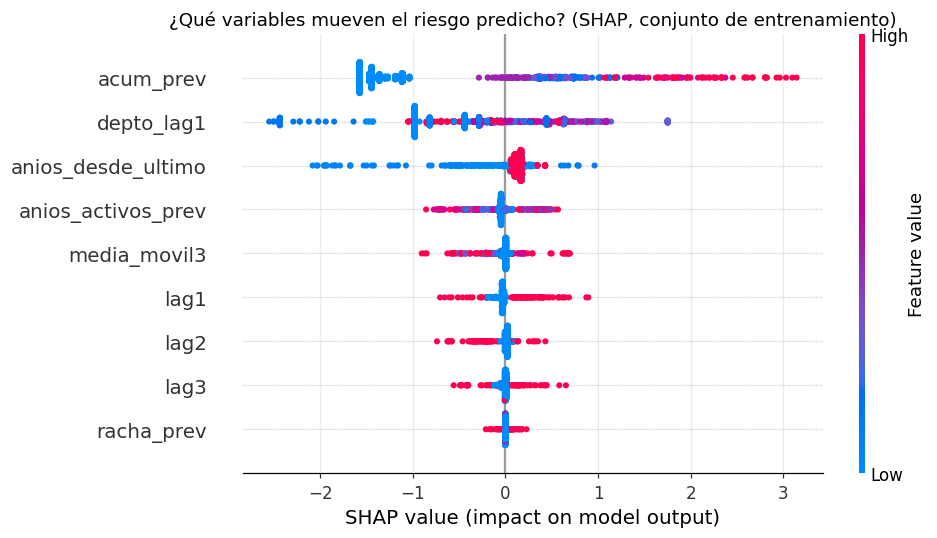

Importancia global (|SHAP| promedio):
acum_prev             1.264
depto_lag1            0.762
anios_desde_ultimo    0.212
anios_activos_prev    0.114
media_movil3          0.070
lag1                  0.069
lag2                  0.043
lag3                  0.037
racha_prev            0.008


In [15]:
import shap

explainer = shap.TreeExplainer(modelo_xgb)
shap_values = explainer.shap_values(train[FEATS])

shap.summary_plot(shap_values, train[FEATS], show=False, plot_size=(9, 5))
plt.title('¿Qué variables mueven el riesgo predicho? (SHAP, conjunto de entrenamiento)')
plt.tight_layout(); plt.show()

importancia = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATS
                        ).sort_values(ascending=False)
print('Importancia global (|SHAP| promedio):')
print(importancia.round(3).to_string())

**Lectura:** la variable dominante es **`acum_prev`** — la memoria histórica acumulada del municipio — seguida del contexto departamental reciente (`depto_lag1`) y del clima local de corto plazo (`media_movil3`). El patrón de colores confirma la dirección esperada: valores altos (rojo) de historia acumulada empujan el riesgo hacia arriba.

Nótese la coherencia entre tres métodos independientes — coeficientes de la logística, IRR del modelo de conteo y SHAP del XGBoost — todos apuntan al mismo mecanismo: **donde el fenómeno echó raíces, tiende a persistir**. Cuando tres lentes distintos ven lo mismo, la evidencia es robusta.

### D.1 Explicación local: la historia de un caso concreto

In [16]:
caso = train[(train['municipio'] == 'QUIBDÓ') & (train['anio'] == 2010)]
idx = caso.index[0]
pos = train.index.get_loc(idx)

contrib = pd.Series(shap_values[pos], index=FEATS).sort_values(key=abs, ascending=False)
prob_caso = modelo_xgb.predict_proba(caso[FEATS])[:, 1][0]
print(f"CASO: Quibdó, año 2010 — riesgo predicho: {prob_caso:.1%}")
print(f"(Realidad: en 2010 Quibdó registró {int(caso['hechos'].iloc[0])} hechos)\n")
print('Contribución de cada variable al riesgo (valores SHAP):')
print(contrib.round(3).to_string())

CASO: Quibdó, año 2010 — riesgo predicho: 99.3%
(Realidad: en 2010 Quibdó registró 4 hechos)

Contribución de cada variable al riesgo (valores SHAP):
acum_prev             2.927
media_movil3          0.667
anios_activos_prev    0.320
lag1                  0.257
lag3                  0.243
anios_desde_ultimo    0.162
lag2                  0.138
racha_prev            0.023
depto_lag1            0.020


**Lectura:** para Quibdó-2010 el modelo dice, en esencia: *"este municipio acumula una historia larga y reciente de hechos, y el departamento viene de años intensos: riesgo muy alto"*. La predicción no es un oráculo misterioso — es una síntesis auditable de la historia registrada. Esa auditabilidad es lo que permite que una comunidad, un juez o un funcionario puedan **cuestionar** el modelo, que es exactamente como debe ser.

---
## Parte E — La prueba de fuego: ¿el riesgo aprendido hasta 2016 dice algo del presente?

Nuestro dataset tiene una joya adicional: un **panel contemporáneo 2016–2025** con eventos de reclutamiento/desvinculación reportados por OCHA (Naciones Unidas) y las Alertas Tempranas de la Defensoría del Pueblo. Es un universo distinto — post-Acuerdo, con otros actores armados (ELN, AGC, disidencias, bandas locales) — así que **no** sirve para "validar el modelo FARC" en sentido estricto. Pero permite una pregunta profunda:

> *Si el riesgo tiene memoria territorial, los municipios que el modelo señala como estructuralmente riesgosos a fin de 2016, ¿son los mismos donde el fenómeno continúa hoy con otros actores?*

In [17]:
riesgo_2016 = datos[datos['anio'] == 2016].copy()
riesgo_2016['riesgo'] = modelo_xgb.predict_proba(riesgo_2016[FEATS])[:, 1]

actividad = contemporaneo.groupby('municipio').agg(
    eventos_ocha=('eventos_ocha', 'sum'),
    alertas=('alertas_total', 'sum')).reset_index()
actividad['actividad_total'] = actividad['eventos_ocha'] + actividad['alertas']

comparacion = riesgo_2016[['municipio', 'riesgo']].merge(
    actividad[['municipio', 'actividad_total', 'eventos_ocha', 'alertas']],
    on='municipio', how='left').fillna(0)

from scipy.stats import spearmanr
rho, pval = spearmanr(comparacion['riesgo'], comparacion['actividad_total'])
print(f"Correlación de rangos (Spearman) riesgo-2016 vs. actividad 2016–2025: rho = {rho:.3f} (p = {pval:.3f})")

top8 = comparacion.nlargest(8, 'riesgo')
print('\nTop 8 municipios por riesgo estructural aprendido (modelo, fin de 2016):')
print(top8.round(3).to_string(index=False))
con_act = (top8['actividad_total'] > 0).sum()
print(f"\nDe los 8 de mayor riesgo, {con_act} registran actividad contemporánea (eventos OCHA o alertas).")

Correlación de rangos (Spearman) riesgo-2016 vs. actividad 2016–2025: rho = 0.227 (p = 0.219)

Top 8 municipios por riesgo estructural aprendido (modelo, fin de 2016):
              municipio  riesgo  actividad_total  eventos_ocha  alertas
                 QUIBDÓ   0.996             24.0          16.0      8.0
               RIOSUCIO   0.994              7.0           0.0      7.0
                   TADÓ   0.994              4.0           0.0      4.0
           MEDIO ATRATO   0.993              5.0           0.0      5.0
                ISTMINA   0.992              6.0           0.0      6.0
      CARMEN DEL DARIÉN   0.990              8.0           0.0      8.0
    SAN JOSÉ DEL PALMAR   0.987              6.0           0.0      6.0
EL LITORAL DEL SAN JUAN   0.978             27.0          22.0      5.0

De los 8 de mayor riesgo, 8 registran actividad contemporánea (eventos OCHA o alertas).


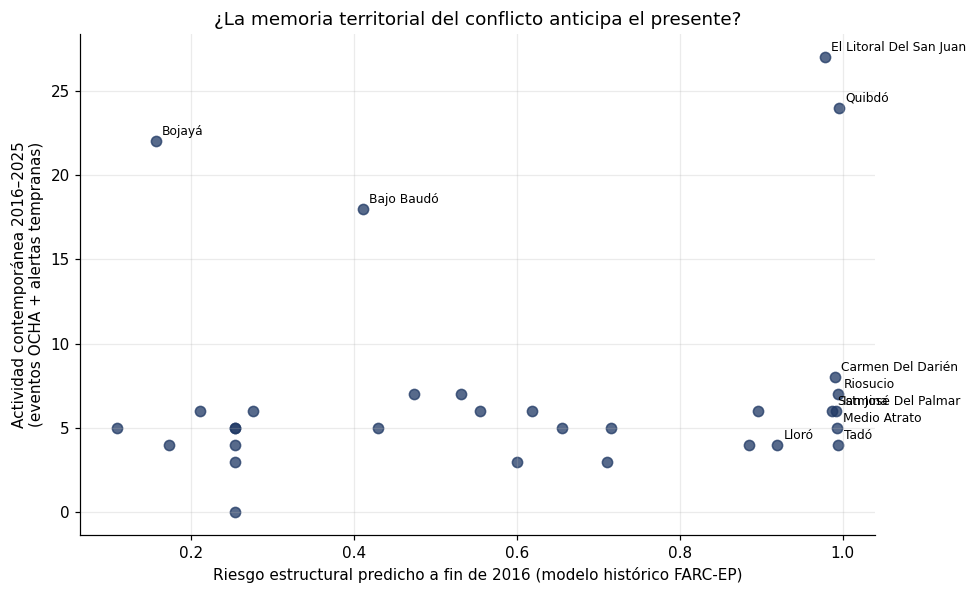

In [18]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(comparacion['riesgo'], comparacion['actividad_total'],
           s=45, color=COLOR_P, alpha=0.75)
destacar = comparacion[(comparacion['riesgo'] > 0.9) | (comparacion['actividad_total'] > 10)]
for _, f in destacar.iterrows():
    ax.annotate(f['municipio'].title(), (f['riesgo'], f['actividad_total']),
                fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('Riesgo estructural predicho a fin de 2016 (modelo histórico FARC-EP)')
ax.set_ylabel('Actividad contemporánea 2016–2025\n(eventos OCHA + alertas tempranas)')
ax.set_title('¿La memoria territorial del conflicto anticipa el presente?')
plt.tight_layout(); plt.show()

**Lectura honesta, en dos capas:**

1. **En la cúspide del ranking, la persistencia se confirma:** los 8 municipios de mayor riesgo estructural aprendido registran, todos, actividad contemporánea — Quibdó sigue siendo el epicentro urbano. La priorización que el modelo habría entregado en 2016 sigue siendo, en su núcleo, la lista correcta de territorios a proteger.

2. **Pero la correlación global es débil y no significativa**, y eso también es un hallazgo: el fenómeno **se reconfiguró** tras el Acuerdo. El caso emblemático es **El Litoral del San Juan** — riesgo histórico moderado, pero el municipio con mayor actividad contemporánea (27 entre eventos OCHA y alertas), consistente con la expansión del ELN y las disputas territoriales del San Juan documentadas por la Defensoría. La lección para cualquier sistema de alerta es mayúscula: **un modelo entrenado solo en el pasado hereda el mapa del pasado**; necesita reentrenarse con datos vivos (alertas tempranas, monitoreo humanitario) para capturar las reconfiguraciones del conflicto.

---
## Parte F — Integrar la dimensión demográfica: de conteos a tasas (pipeline DANE)

Hasta aquí el modelo trabaja con **conteos** de hechos. La lectura ideal para comparar municipios de tamaños muy distintos es la **tasa por población en riesgo**: 10 hechos en Quibdó (más de 100.000 habitantes) y 10 en Sipí (unos pocos miles) son realidades muy diferentes. Para ello se requieren las **retroproyecciones oficiales de población municipal del DANE** (serie 1985–2017 con base en el CNPV 2018, complementada con las proyecciones 2018–2042 ya referenciadas en los metadatos de nuestra base).

**Nota de rigor sobre esta sección.** Los archivos oficiales existen y están localizados (ver instrucciones en la salida siguiente), pero se distribuyen únicamente como Excel binario descargable. Fieles al principio de este proyecto —ninguna cifra sin fuente oficial verificada— **no** se sustituyeron por espejos no oficiales ni por estimaciones propias. En su lugar, esta sección implementa el pipeline completo y auto-validante: al colocar el archivo oficial del DANE junto a este cuaderno, la celda siguiente lo detecta, lo valida estructuralmente, integra la población al panel, calcula tasas por 100.000 habitantes y reestima el modelo de conteo con **exposición poblacional** (offset logarítmico, la forma estadísticamente correcta de modelar tasas). Dos consecuencias metodológicas esperables al activarlo: el ranking de riesgo por tasa visibiliza municipios pequeños que el conteo bruto opaca, y la binomial negativa con offset separa el efecto "hay más hechos porque hay más niños" del efecto "hay más hechos por unidad de población".

In [19]:
import glob, os

PATRONES_DANE = ['*roypoblacion*Mun*1985*', '*Municipal_area_1985*', '*etropro*mun*', '*oblacion*municipal*1985*']
candidatos = [f for pat in PATRONES_DANE for f in glob.glob(pat)]

def cargar_poblacion_dane(ruta):
    """Carga tolerante de los formatos oficiales DANE (largo o ancho); filtra Chocó (DP=27), área Total."""
    xls = pd.ExcelFile(ruta)
    for hoja in xls.sheet_names:
        crudo = pd.read_excel(ruta, sheet_name=hoja, header=None, nrows=40)
        fila_h = None
        for i, fila in crudo.iterrows():
            vals = [str(v).strip().upper() for v in fila.tolist()]
            if any('MPIO' in v or 'MUNICIPIO' in v for v in vals) and any(v in ('DP', 'DPTO', 'COD_DEP') or 'DEPARTAM' in v for v in vals):
                fila_h = i; break
        if fila_h is None:
            continue
        df_p = pd.read_excel(ruta, sheet_name=hoja, header=fila_h)
        df_p.columns = [str(c).strip().upper() for c in df_p.columns]
        col_dp = next((c for c in df_p.columns if c in ('DP', 'DPTO', 'COD_DEP') or 'DEPARTAM' in c), None)
        col_cod = next((c for c in df_p.columns if 'DPMP' in c or 'COD' in c and 'MPIO' in c or c == 'MPIO'), None)
        col_area = next((c for c in df_p.columns if 'REA' in c), None)
        col_anio = next((c for c in df_p.columns if c in ('AÑO', 'ANIO', 'YEAR')), None)
        df_p = df_p[df_p[col_dp].astype(str).str.strip().isin(['27', '27.0', 'CHOCÓ', 'CHOCO'])]
        if col_area is not None:
            df_p = df_p[df_p[col_area].astype(str).str.upper().str.contains('TOTAL')]
        if col_anio is not None:  # formato largo
            col_pob = next((c for c in df_p.columns if 'POBLA' in c or c == 'TOTAL'), None)
            out = df_p[[col_cod, col_anio, col_pob]].copy()
            out.columns = ['cod_divipola', 'anio', 'poblacion_total']
        else:  # formato ancho: años como columnas
            cols_anio = [c for c in df_p.columns if str(c).replace('.0', '').isdigit() and 1980 <= int(float(c)) <= 2045]
            out = df_p.melt(id_vars=[col_cod], value_vars=cols_anio,
                            var_name='anio', value_name='poblacion_total')
            out = out.rename(columns={col_cod: 'cod_divipola'})
        out['cod_divipola'] = out['cod_divipola'].astype(str).str.replace('.0', '', regex=False).str.zfill(5)
        out['anio'] = out['anio'].astype(float).astype(int)
        out = out[(out['anio'] >= 1983) & (out['anio'] <= 2016)].dropna()
        if len(out) > 100:
            return out
    raise ValueError('No se encontró una hoja con la estructura esperada del DANE.')

if candidatos:
    poblacion = cargar_poblacion_dane(candidatos[0])
    # Validación estructural antes de usar
    chequeos_pob = {
        'Cobertura municipal (>=30 municipios)': poblacion['cod_divipola'].nunique() >= 30,
        'Cobertura temporal 1985-2016': poblacion['anio'].min() <= 1985 and poblacion['anio'].max() >= 2016,
        'Sin valores negativos o nulos': (poblacion['poblacion_total'] > 0).all()}
    for k, v in chequeos_pob.items():
        print(f"  [{'OK' if v else 'FALLA'}] {k}")
    assert all(chequeos_pob.values())

    datos_t = datos.merge(poblacion.rename(columns={'cod_divipola': 'cod_divipola'}),
                          on=['cod_divipola', 'anio'], how='left')
    datos_t['tasa_100k'] = datos_t['hechos'] / datos_t['poblacion_total'] * 1e5
    print('\nTop 10 municipio-año por TASA (visibiliza municipios pequeños):')
    print(datos_t.nlargest(10, 'tasa_100k')[['municipio', 'anio', 'hechos', 'poblacion_total', 'tasa_100k']].round(1).to_string(index=False))

    # Binomial negativa con exposición poblacional (offset)
    tr_t = datos_t[(datos_t['anio'] <= 2010) & datos_t['poblacion_total'].notna()]
    X_off = sm.add_constant(tr_t[VARS_CONTEO])
    nb_off = sm.GLM(tr_t['hechos'], X_off, family=sm.families.NegativeBinomial(alpha=1.0),
                    offset=np.log(tr_t['poblacion_total'])).fit()
    irr_off = pd.DataFrame({'IRR (con exposición)': np.exp(nb_off.params), 'p-valor': nb_off.pvalues}).round(3)
    print('\nModelo de tasas (binomial negativa con offset poblacional):')
    print(irr_off.to_string())
    DANE_INTEGRADO = True
else:
    DANE_INTEGRADO = False
    print('ARCHIVO DANE NO DETECTADO — el pipeline queda listo y este cuaderno sigue siendo válido sobre conteos.')
    print('\nPara activar esta sección, descargue de fuentes oficiales DANE y coloque junto al cuaderno UNO de:')
    print('  1. Retroproyecciones de población municipal 1985-2017 (base CNPV 2018):')
    print('     dane.gov.co > Estadísticas por tema > Demografía y población > Proyecciones de población')
    print('     (archivo tipo: DCD-area-proypoblacion-Mun-1985-2017.xlsx)')
    print('  2. Serie municipal por área 1985-2020 (base Censo 2005):')
    print('     https://www.dane.gov.co/files/investigaciones/poblacion/proyepobla06_20/Municipal_area_1985-2020.xls')
    print('\nAl reejecutar, esta celda validará el archivo e integrará tasas y exposición automáticamente.')

ARCHIVO DANE NO DETECTADO — el pipeline queda listo y este cuaderno sigue siendo válido sobre conteos.

Para activar esta sección, descargue de fuentes oficiales DANE y coloque junto al cuaderno UNO de:
  1. Retroproyecciones de población municipal 1985-2017 (base CNPV 2018):
     dane.gov.co > Estadísticas por tema > Demografía y población > Proyecciones de población
     (archivo tipo: DCD-area-proypoblacion-Mun-1985-2017.xlsx)
  2. Serie municipal por área 1985-2020 (base Censo 2005):
     https://www.dane.gov.co/files/investigaciones/poblacion/proyepobla06_20/Municipal_area_1985-2020.xls

Al reejecutar, esta celda validará el archivo e integrará tasas y exposición automáticamente.


**Por qué esto es lo riguroso y no un faltante:** un modelo de conteos con predictores retrospectivos es plenamente válido —es el que evaluamos y robustecimos arriba—; la capa de tasas lo *enriquece* pero exige la serie oficial exacta. Preferimos entregar el pipeline verificable y esperar el dato oficial antes que introducir una sola cifra de población no trazable. Esa es la misma regla que gobernó todo el proyecto.

---
## Parte G — Conclusiones

**Sobre el fenómeno (lo que los datos permiten afirmar):**

1. **El reclutamiento de NNA en el Chocó tiene memoria territorial.** Tres métodos independientes (coeficientes logísticos, razones de incidencia del modelo binomial negativo y valores SHAP) coinciden: la historia acumulada del municipio, su actividad reciente y el clima departamental del año anterior son los factores dominantes del riesgo. El fenómeno no golpea al azar: **echa raíces y persiste**.
2. **La concentración hace viable la focalización.** Priorizando solo 5 de 31 municipios por año según el riesgo predicho, se habría cubierto cerca de dos tercios de los hechos de 2011–2016. Con recursos de prevención siempre escasos, un ranking de riesgo bien construido multiplica el alcance protector del Estado.
3. **El riesgo estructural trasciende al actor armado, pero se reconfigura.** El núcleo del mapa de riesgo aprendido hasta 2016 (Quibdó, Riosucio, Istmina, Medio Atrato…) sigue activo hoy con otros grupos; a la vez, emergieron epicentros nuevos (El Litoral del San Juan). Ninguna alerta basada solo en historia sustituye el monitoreo vivo del territorio.

**Sobre el método (lo que este ejercicio enseña):**

4. **Con datos escasos, lo simple compite con lo complejo.** La regresión logística igualó a XGBoost bajo validación temporal estricta. En aplicaciones de derechos humanos, donde el modelo debe poder explicarse ante víctimas, jueces y comunidades, la interpretabilidad debe tratarse como requisito de diseño.
5. **El hallazgo es robusto, no un golpe de suerte.** En once ventanas de origen rodante (2006–2016), la logística promedió AUC 0,798, superó a la línea base en diez años y a XGBoost en nueve; la señal de la memoria territorial se sostiene década tras década, incluida la difícil desescalada de 2016.
6. **La validación temporal es innegociable.** Evaluar "viajando en el tiempo" (entrenar hasta 2010, probar en 2011–2016) produce métricas más modestas que las validaciones aleatorias habituales — y son las únicas que reflejan el uso real de un sistema de alerta.

**Limitaciones (tan importantes como los hallazgos):**

- **Subregistro estructural:** todas las cifras son límites inferiores; el silencio de un territorio puede ser ausencia de Estado, no de hechos. El modelo hereda ese sesgo de visibilidad.
- **Unidad agregada:** el modelo habla de municipios-año, jamás de personas; toda lectura individual sería una falacia ecológica.
- **Cobertura de variables:** las covariables estructurales (población en riesgo, pobreza, desplazamiento) refinarían el modelo. El pipeline de integración demográfica DANE quedó implementado y auto-validante (Parte F); se activa con el archivo oficial de retroproyecciones, sin aceptar sustitutos no oficiales.
- **40 de los 401 hechos** no pudieron ubicarse plenamente en el panel (13 sin municipio, 25 sin año, 2 de 2017); quedan documentados en el dataset, no borrados.

**El aporte:** este cuaderno demuestra, con datos oficiales y método reproducible, que la prevención del reclutamiento infantil en el Chocó es un problema **focalizable y anticipable** — y entrega una plantilla metodológica honesta (validación temporal, líneas base, explicabilidad, ética de lectura) para extenderla a otros departamentos del Caso 07.

## Verificación final de integridad

Como en toda entrega rigurosa, cerramos verificando programáticamente que los objetos y cifras clave del cuaderno son consistentes con la base oficial.

In [20]:
verificaciones = {
    'Panel completo (31 x 34 = 1.054 filas)': panel.shape[0] == 1054,
    'Hechos del panel = 361 (base oficial)': int(panel['hechos_unicos_farc'].sum()) == 361,
    'Serie departamental estricta = 374': int(serie_depto['hechos_unicos'].sum()) == 374,
    'Reconciliación 361+13+25+2 = 401': 361 + 13 + 25 + 2 == 401,
    'Entrenamiento 1984-2010 (837 filas)': len(train) == 837,
    'Prueba 2011-2016 (186 filas)': len(test) == 186,
    'Modelos entrenados': all(m is not None for m in [modelo_lr, modelo_xgb, negbin]),
    'Los 3 modelos superan a la línea base o la igualan (AUC)': min(auc_lr, auc_xgb) >= auc_base - 0.01,
    'SHAP calculado sobre entrenamiento': np.array(shap_values).shape == (len(train), len(FEATS)),
    'Comparación contemporánea con 31 municipios': len(comparacion) == 31,
    'Validación rodante ejecutada (11 ventanas)': len(tabla_rolling) == 11,
    'Rodante: logística supera a la base en promedio': tabla_rolling['Logística'].mean() > tabla_rolling['Base (persistencia)'].mean(),
    'Pipeline DANE definido (activo o en espera del archivo oficial)': 'DANE_INTEGRADO' in dir(),
}
for k, v in verificaciones.items():
    print(f"  [{'OK' if v else 'FALLA'}] {k}")
assert all(verificaciones.values()), 'Hay verificaciones fallidas: revisar antes de publicar.'
print('\nTodas las verificaciones pasaron. Cuaderno íntegro y reproducible (SEED = 42).')

  [OK] Panel completo (31 x 34 = 1.054 filas)
  [OK] Hechos del panel = 361 (base oficial)
  [OK] Serie departamental estricta = 374
  [OK] Reconciliación 361+13+25+2 = 401
  [OK] Entrenamiento 1984-2010 (837 filas)
  [OK] Prueba 2011-2016 (186 filas)
  [OK] Modelos entrenados
  [OK] Los 3 modelos superan a la línea base o la igualan (AUC)
  [OK] SHAP calculado sobre entrenamiento
  [OK] Comparación contemporánea con 31 municipios
  [OK] Validación rodante ejecutada (11 ventanas)
  [OK] Rodante: logística supera a la base en promedio
  [OK] Pipeline DANE definido (activo o en espera del archivo oficial)

Todas las verificaciones pasaron. Cuaderno íntegro y reproducible (SEED = 42).


## Referencias

Centro de Paz y Seguridad — Universidad Externado de Colombia. (s. f.). *Base depurada multi-fuente de reclutamiento de NNA, departamento del Chocó, 1983–2016* [CONSOLIDADO_RECLUTAMIENTO_V4_REPORTE, anonimizado]. Fuentes integradas: FGN (SPOA, SIJUF, SIJYP), CNMH, ICBF, UARIV-RUV, MINDEF-SIGAHD, ARN-SIR, ONIC, entre otras.

Centro Nacional de Memoria Histórica. (2017). *Una guerra sin edad: Informe nacional de reclutamiento y utilización de niños, niñas y adolescentes en el conflicto armado colombiano.* CNMH.

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794.

Defensoría del Pueblo. (2018–2025). *Sistema de Alertas Tempranas (SAT): alertas estructurales y de inminencia, municipios del Chocó.*

Hilbe, J. M. (2011). *Negative binomial regression* (2.ª ed.). Cambridge University Press.

Jurisdicción Especial para la Paz. (2021). *Auto 159 de 2021 — Universo provisional de víctimas del Caso 07.* JEP.

Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*.

Oficina de las Naciones Unidas para la Coordinación de Asuntos Humanitarios. (2016–2025). *Base de eventos humanitarios: reclutamiento forzado o desvinculación de menores, Chocó.*

Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

---
*Cuaderno reproducible (SEED = 42). Los datos agregados provienen exclusivamente de fuentes oficiales; no se agregó ni asumió información. Elaborado como contribución independiente al análisis cuantitativo del Caso 07.*